In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))
# #         break

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
# !pip install clip --quiet
# !pip uninstall -y clip
# direct clip gives an issue

# !pip install openai-clip --quiet
# !pip install git+https://github.com/openai/CLIP.git --quiet
!pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-tlaazwlt
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-tlaazwlt
  Resolved https://github.com/openai/CLIP.git to commit dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1
  Preparing metadata (setup.py) ... - done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.4/54.4 kB 2.4 MB/s eta 0:00:00
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369489 sha256=ab9900c31c7eca41a004285456f5464cd30b8f898d039c854f62a0fed72be4f0
  Stored in directory: /tmp/pip-ephem-wheel-cache-s4ngzx0f/wheels/da/2b/4c/d6691fa9597aac8bb85d2ac13b112deb897d5b50f5ad9a37e4
Successfully built clip


In [3]:
import clip

In [4]:
import json
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# from transformers import CLIPProcessor, CLIPModel

In [5]:
# load model and processor
# model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
# processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# pretrained-model
model, preprocess = clip.load("ViT-B/32", device = device, jit=False)
# model is for images
# preprocess is for texts

100%|███████████████████████████████████████| 338M/338M [00:04<00:00, 76.8MiB/s]


In [7]:
# paths

train_json_path = '/kaggle/input/indo-fashion-dataset/train_data.json'

# input data as a list
input_data = []
with open(train_json_path, 'r') as file:
    for line in file:
        obj = json.loads(line)
        input_data.append(obj)
        
input_data[:2]

[{'image_url': 'https://m.media-amazon.com/images/I/81XKaSKvlyL._AC_UL320_.jpg',
  'image_path': 'images/train/0.jpeg',
  'brand': 'Womanista',
  'product_title': "Women's Georgette Saree with Blouse Piece (TKIM811_Black_Free Size)",
  'class_label': 'saree'},
 {'image_url': 'https://m.media-amazon.com/images/I/91dDMDg+QTL._AC_UL320_.jpg',
  'image_path': 'images/train/1.jpeg',
  'brand': 'Yashika',
  'product_title': 'Women Linen Printed Sarees Free Size (BEE)',
  'class_label': 'saree'}]

In [8]:
train_image_path = '/kaggle/input/indo-fashion-dataset/images/train/'

list_image_path = []
list_txt = []

for item in input_data:
    img_path = train_image_path + item['image_path'].split('/')[-1]
    list_image_path.append(img_path)

    #As we have image text pair, we use product title as description.
    caption = item['product_title'][:100]
    list_txt.append(caption)

In [9]:
list_image_path[:5], list_txt[:5]

(['/kaggle/input/indo-fashion-dataset/images/train/0.jpeg',
  '/kaggle/input/indo-fashion-dataset/images/train/1.jpeg',
  '/kaggle/input/indo-fashion-dataset/images/train/2.jpeg',
  '/kaggle/input/indo-fashion-dataset/images/train/3.jpeg',
  '/kaggle/input/indo-fashion-dataset/images/train/4.jpeg'],
 ["Women's Georgette Saree with Blouse Piece (TKIM811_Black_Free Size)",
  'Women Linen Printed Sarees Free Size (BEE)',
  'Organza Floral Print Saree with Blouse Piece(WM1312_ Off White & Pink_ Onesize)',
  "Women's Digital Cotton Linen Blend Saree with Unstitched Blouse Piece(DigiPatta)",
  "Designer Sarees Women's Banarasi Cotton Silk Saree With Blouse Piece."])

In [10]:
# This design is quite efficient
# Text tokenization is done once at initialization, saving computation during training.
# Images are loaded and preprocessed on demand, saving memory.

# Define a custom dataset
class image_title_dataset():
    def __init__(self, list_image_path, list_txt):
        self.image_path = list_image_path
        self.title = clip.tokenize(list_txt)

    def __len__(self):
        return len(self.title)

    def __getitem__(self, idx):
        # It loads and preprocesses the image on-the-fly
        # when an item is requested. This is memory-efficient 
        # as it doesn't load all images into memory at once
        image = preprocess(Image.open(self.image_path[idx]))
        title = self.title[idx]
        
        # returned is the preprocessed image and the preprocessed (tokenized) title
        return image, title

In [11]:
# to check with only 5000 examples
# dataset = image_title_dataset(list_image_path[:10000], list_txt[:10000])
dataset = image_title_dataset(list_image_path, list_txt)
train_dataloader = DataLoader(dataset, batch_size=256, shuffle=True) 

In [12]:
len(next(iter(train_dataloader)))

2

In [13]:
# next(iter(train_dataloader))[0].shape, next(iter(train_dataloader))[1].shape

In [14]:
# next(iter(train_dataloader))[1]

In [15]:
# Function to convert model's parameters to FP32 format
#This is done so that our model loads in the provided memory.
# def convert_models_to_fp32(model): 
#     for p in model.parameters(): 
#         p.data = p.data.float() 
#         p.grad.data = p.grad.data.float() 

In [16]:
optimizer = torch.optim.Adam(model.parameters(), lr=5e-5, betas=(0.9, 0.98),
                            eps=1e-6, weight_decay=0.2)

loss_img = nn.CrossEntropyLoss()
loss_txt = nn.CrossEntropyLoss()

**Ground truth and loss calculation:**

The ground truth is indeed defined as a simple range of values, which might seem counterintuitive at first. However, this approach is actually implementing a form of contrastive learning. Here's how it works:

- The `ground_truth` tensor is a range from 0 to batch_size-1.
- `logits_per_image` and `logits_per_text` are matrices of **size `(batch_size, batch_size)`**.
    - `logits_per_image` and `logits_per_text` are similarity matrices.
    - Each row in `logits_per_image` represents how similar one image is to all the text descriptions in the batch.
    - Similarly, each row in `logits_per_text` represents how similar one text description is to all the images in the batch.
- For each row in these matrices, the correct match should be along the diagonal.



The CrossEntropyLoss is then used to push the model to maximize the similarity between the correct image-text pairs while minimizing the similarity between incorrect pairs. In essence, it's teaching the model to match each image with its corresponding text description within the batch.\
This approach leverages the batch itself as a set of negative examples, which is a clever way to perform contrastive learning without explicitly defining negative pairs.

By using CrossEntropyLoss with this setup, we're essentially saying:

- For each image (or text), make its similarity highest with its corresponding text (or image).
- At the same time, minimize its similarity with all other texts (or images) in the batch.


Positive and Negative Samples:

- Each image-text pair in the batch serves as a positive example for itself.
- All other combinations in the batch serve as negative examples.
- This clever use of the batch as its own set of negative examples is what makes this approach efficient.

This approach allows the model to learn rich, multi-modal representations without needing explicit labels.
It can capture nuanced relationships between visual and textual information.
The learned representations are often highly transferable to other tasks.

In [17]:
# training 
n_epochs = 4

for epoch in range(n_epochs):
    pbar = tqdm(train_dataloader, total = len(train_dataloader))
    
    for batch in pbar:
        optimizer.zero_grad()
        images, texts = batch
        images, texts = images.to(device), texts.to(device)
        
        # forward pass
        logits_per_image, logits_per_text = model(images, texts)
        
        # loss is avg of text and image loss
        ground_truth = torch.arange(len(images), dtype=torch.long, device=device)
        total_loss = (loss_img(logits_per_image, ground_truth) + loss_txt(logits_per_text, ground_truth))/2
        
        total_loss.backward()
        
        # gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm = 5)
        optimizer.step()
        
        pbar.set_description(f"Epoch {epoch}/{n_epochs}, Loss: {total_loss.item():.4f}")

Epoch 3/4, Loss: 3.1680: 100%|██████████| 357/357 [21:02<00:00,  3.54s/it]


In [18]:
# inference
# List of clothing items for comparison
clothing_items = [
    "Saree",
    "Lehenga",
    "Women Kurta",
    "Dupatta",
    "Gown",
    "Nehru Jacket",
    "Sherwani",
    "Men Kurta",
    "Men Mojari",
    "Leggings and Salwar",
    "Blouse",
    "Palazzo",
    "Dhoti Pants",
    "Petticoat",
    "Women Mojari"
]
len(clothing_items)

15

In [19]:
# Index of the input data you want to analyze
index_ = 500

# Assuming 'input_data' is a list of JSON-like objects with image information
image_json = input_data[index_]

# Construct the full path to the image file using the given 'image_path'
image_path = os.path.join("/kaggle/input/indo-fashion-dataset", image_json['image_path'])
image_class = image_json['class_label']
image_path, image_class

('/kaggle/input/indo-fashion-dataset/images/train/500.jpeg', 'saree')

In [20]:
# Preprocess the image and move it to the appropriate device (CPU or GPU)
image = preprocess(Image.open(image_path)).unsqueeze(0).to(device)
image.shape

torch.Size([1, 3, 224, 224])

In [21]:
# Tokenize and move the clothing item names to the appropriate device
text = torch.cat([clip.tokenize(f"a photo of a {c}") for c in clothing_items]).to(device)
text.shape

torch.Size([15, 77])


Top predictions:

          Blouse: 10.06%
      Men Mojari: 9.23%
    Women Mojari: 8.60%
    Nehru Jacket: 8.14%
            Gown: 7.59%


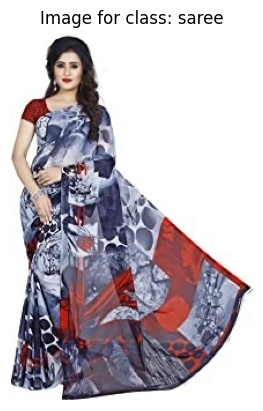

In [22]:
# Perform inference
with torch.no_grad():
    # Encode image and text
    image_features = model.encode_image(image)
    text_features = model.encode_text(text)
    
    # Calculate similarity scores between image and text
    logits_per_image, logits_per_text = model(image, text)
    probs = logits_per_image.softmax(dim=-1).cpu().numpy()

# Normalize image and text features
# normalized to have unit length
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)

# Calculate similarity scores
# dot product measures how similar the image embedding is to each text embedding.
# softmax converts it into probabilities
similarity = (100.0 * image_features @ text_features.T).softmax(dim=-1)
values, indices = similarity[0].topk(5)

# Print the top predictions
print("\nTop predictions:\n")
for value, index in zip(values, indices):
    print(f"{clothing_items[index]:>16s}: {100 * value.item():.2f}%")

# Display the image with its class label
plt.imshow(plt.imread(image_path))
plt.title(f"Image for class: {image_class}")
plt.axis('off')
plt.show()

In [23]:
# saving the model
torch.save(model.state_dict(), '/kaggle/working/trained_clip_model.pth')

In [24]:
# load the model 
import torch
import clip

# Load the CLIP model architecture
device = "cuda" if torch.cuda.is_available() else "cpu"
model, preprocess = clip.load("ViT-B/32", device=device, jit=False)

# Load the saved state dictionary
model.load_state_dict(torch.load('/kaggle/working/trained_clip_model.pth'))

# Set the model to evaluation mode
model.eval()

CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (transformer): Transformer(
      (resblocks): Sequential(
        (0): ResidualAttentionBlock(
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): QuickGELU()
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        )
        (1): ResidualAttentionBlock(
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          

In [25]:
def inferring_from_model(sample_index):
    image_json = input_data[sample_index]

    # Construct the full path to the image file using the given 'image_path'
    image_path = os.path.join("/kaggle/input/indo-fashion-dataset", image_json['image_path'])
    image_class = image_json['class_label']
    image_path, image_class
    
    with torch.no_grad():
        # Encode image and text
        image_features = model.encode_image(image)
        text_features = model.encode_text(text)
        
        
    # Normalize image and text features
    # normalized to have unit length
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features /= text_features.norm(dim=-1, keepdim=True)

    # Calculate similarity scores
    # dot product measures how similar the image embedding is to each text embedding.
    # softmax converts it into probabilities
    similarity = (100.0 * image_features @ text_features.T).softmax(dim=-1)
    values, indices = similarity[0].topk(5)

    # Print the top predictions
    print("\nTop predictions:\n")
    for value, index in zip(values, indices):
        print(f"{clothing_items[index]:>16s}: {100 * value.item():.2f}%")

    # Display the image with its class label
    plt.imshow(plt.imread(image_path))
    plt.title(f"Image for class: {image_class}")
    plt.axis('off')
    plt.show()
    


Top predictions:

          Blouse: 10.06%
      Men Mojari: 9.23%
    Women Mojari: 8.60%
    Nehru Jacket: 8.14%
            Gown: 7.59%


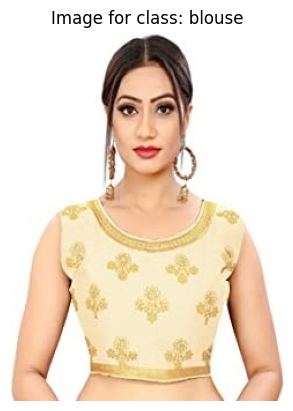

In [26]:
inferring_from_model(sample_index = 15300)